In [2]:
import numpy as np
from hmmlearn import hmm
from scipy import stats
import matplotlib.pyplot as plt

#Subiectul 1 - Model Markov Ascuns

In [11]:
camere = ["1", "2", "3", "4"]
culori= { "red" : 0, "green" : 1, "blue" : 2 }

B = np.array([[0.7, 0.2, 0.1],
              [0.2, 0.6, 0.2],
              [0.1, 0.3, 0.6],
              [0.5, 0.2, 0.3]])
pi = np.full(4, 0.25)

A = np.zeros((4,4))
for i in range(4):
    A[i,i] = p_stai
    A[i, (i-1) % 4] = p_vecin
    A[i, (i+1) % 4] = p_vecin

obs = np.array([culori[c] for c in ["red", "green", "blue", "blue", "red"]])

def viterbi(pi, A, B, obs):
    T, N = len(obs), len(pi)
    delta = np.zeros((T, N))
    psi = np.zeros((T, N), dtype=int)
    delta[0] = pi * B[:, obs[0]]
    for t in range(1, T):
        scor = delta[t - 1][:, None] * A
        psi[t] = scor.argmax(axis=0)
        delta[t] = scor.max(axis=0) * B[:, obs[t]]
    cale = [int(delta[-1].argmax())]
    for t in range(T - 1, 0, -1):
        cale.append(int(psi[t, cale[-1]]))
    return cale[::-1], delta[-1].max(), delta

cale, p, delta = viterbi(pi, A, B, obs)

print("delta_t (camere 1..4):")
for t, row in enumerate(delta):
    print(f"  t={t+1}: " + "  ".join(f"{v:.6f}" for v in row))
print("Viterbi propriu:", [camere[c] for c in cale], f"P = {p:.6e}")

model = hmm.CategoricalHMM(n_components=4, init_params="", params="")
model.startprob_ = pi
model.transmat_ = A
model.emissionprob_ = B

logp, cale_h = model.decode(obs.reshape(-1, 1), algorithm="viterbi")
print("hmmlearn:       ", [camere[c] for c in cale_h], f"P = {np.exp(logp):.6e}")

delta_t (camere 1..4):
  t=1: 0.175000  0.050000  0.025000  0.125000
  t=2: 0.012500  0.052500  0.018750  0.017500
  t=3: 0.002625  0.001875  0.015750  0.002812
  t=4: 0.000141  0.001575  0.000844  0.002363
  t=5: 0.000827  0.000084  0.000118  0.000211
Viterbi propriu: ['1', '2', '3', '4', '1'] P = 8.268750e-04
hmmlearn:        ['1', '2', '3', '4', '1'] P = 8.268750e-04


# Subiectul 3 - Beta-Binomial



Prior        : Beta(2,8)  media=0.2000  mod=0.1250  sd=0.1206  IC95%=[0.028, 0.482]
(a) lot 1    : Beta(7,23)  media=0.2333  mod=0.2143  sd=0.0760  IC95%=[0.103, 0.397]
(b) loturi 1+2: Beta(10,35)  media=0.2222  mod=0.2093  sd=0.0613  IC95%=[0.115, 0.353]
(c) doar lot 2: Beta(5,20)  media=0.2000  mod=0.1739  sd=0.0784  IC95%=[0.071, 0.374]


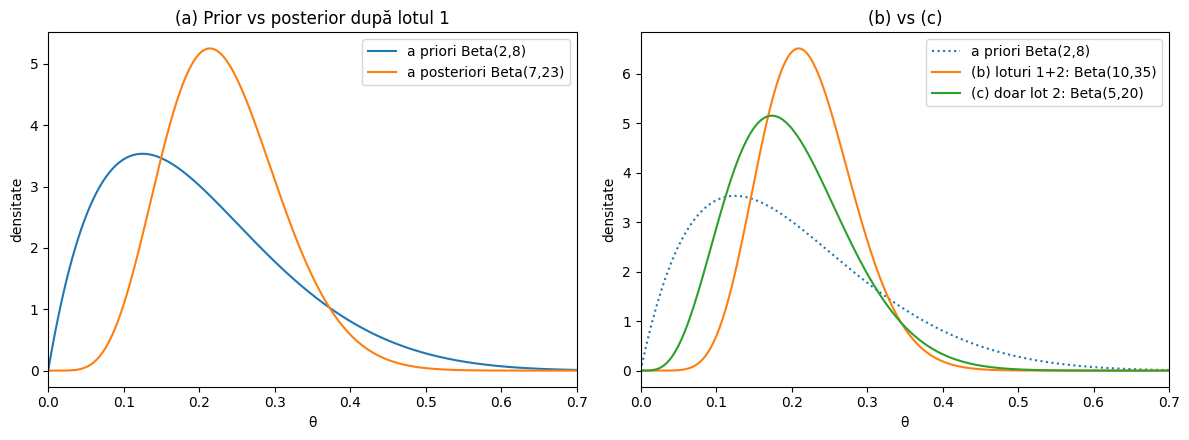

In [4]:
a0, b0 = 2, 8
post1 = (a0 + 5, b0 + 15)
post2 = (post1[0] + 3, post1[1] + 12)
post_c = (a0 + 3, b0 + 12)

def descrie(nume, a, b):
    d = stats.beta(a, b)
    lo, hi = d.ppf([0.025, 0.975])
    print(f"{nume}: Beta({a},{b})  media={d.mean():.4f}  mod={(a-1)/(a+b-2):.4f}  "
          f"sd={d.std():.4f}  IC95%=[{lo:.3f}, {hi:.3f}]")

print()
descrie("Prior        ", a0, b0)
descrie("(a) lot 1    ", *post1)
descrie("(b) loturi 1+2", *post2)
descrie("(c) doar lot 2", *post_c)

x = np.linspace(0, 1, 500)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(x, stats.beta(a0, b0).pdf(x), label="a priori Beta(2,8)")
ax[0].plot(x, stats.beta(*post1).pdf(x), label="a posteriori Beta(7,23)")
ax[0].set_title("(a) Prior vs posterior după lotul 1")
ax[1].plot(x, stats.beta(a0, b0).pdf(x), ":", label="a priori Beta(2,8)")
ax[1].plot(x, stats.beta(*post2).pdf(x), label="(b) loturi 1+2: Beta(10,35)")
ax[1].plot(x, stats.beta(*post_c).pdf(x), label="(c) doar lot 2: Beta(5,20)")
ax[1].set_title("(b) vs (c)")
for a in ax:
    a.set_xlabel("θ"); a.set_ylabel("densitate"); a.legend(); a.set_xlim(0, 0.7)
plt.tight_layout()
plt.savefig("subiectul3_densitati.png", dpi=130)